# Lab 3: Creating and Analyzing Entanglement

Welcome to Lab 3! In the previous lab, we introduced multi-qubit gates, the fundamental tools for creating interactions between qubits. Now, we will use these tools to generate and study one of the most remarkable and foundational phenomena in quantum mechanics: **entanglement**.

Entanglement describes a state where multiple qubits are linked in a way that their individual states are no longer independent, no matter how far apart they are. The state of one qubit is perfectly correlated with the state of the other. The most famous example of such a state is the **Bell state**.

In this lab, we will:
*   Construct the circuit to create a Bell state using Hadamard and CNOT gates.
*   Use the **`statevector_simulator`** to inspect the mathematical state of the system and visualize the entanglement.
*   Use the **`unitary_simulator`** to see the matrix representation of our entanglement circuit.
*   Use the **`qasm_simulator`** to perform measurements and observe the strong correlations that are the hallmark of entanglement.
*   Compare the entangled Bell state to a non-entangled (separable) state to highlight the crucial role of the CNOT gate.

Let's begin our journey into the fascinating world of quantum entanglement.

## 1. Setting Up Our Environment and Importing Libraries

As always, we begin by importing the necessary libraries from Qiskit, Matplotlib, and NumPy. This setup provides us with the tools to build circuits, run simulations, and visualize our results effectively.

In [ ]:
%pip install qiskit qiskit-aer matplotlib

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library

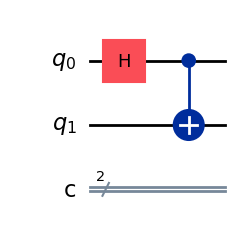

In [ ]:
# The Bell State
qc_bell = QuantumCircuit(2,2,name="qc")
qc_bell.h(0) # H Gate on 1st Qubit
qc_bell.cx(0,1) # CNOT with 1st as Control and 2nd as Target
qc_bell.draw(output='mpl')


Quantum state is: Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


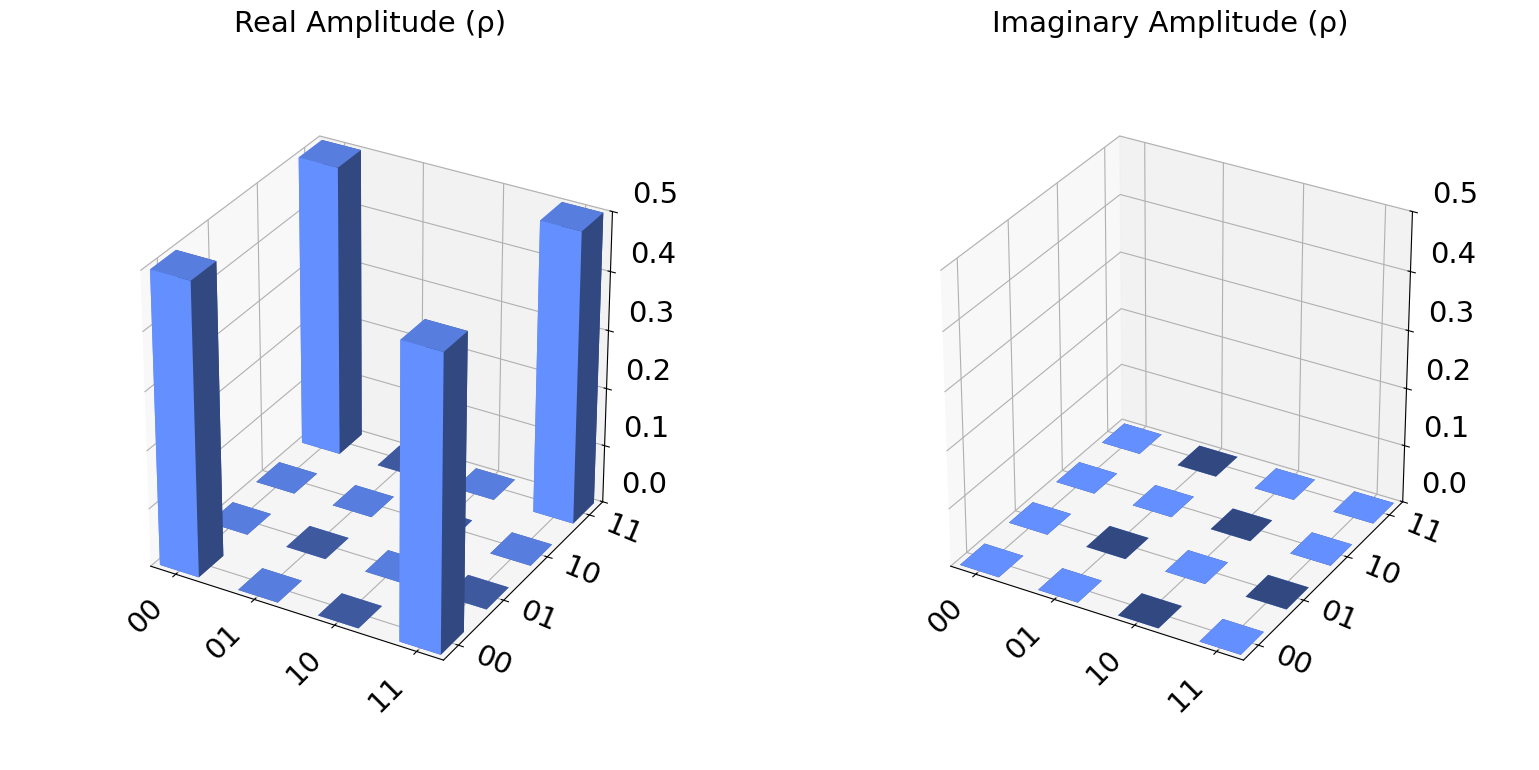

In [ ]:
# To get the eigenvector you should use the statevector simulator in the core of the circuit (without measurements)
simulator_state = Aer.get_backend('statevector_simulator')

# Execute the circuit
job_state = transpile(qc_bell, simulator_state)

# Grab results from the job
result_state = simulator_state.run(job_state).result()

# Returns counts
psi  = result_state.get_statevector(qc_bell)
print("\nQuantum state is:",psi)

# Plot a Density Matrix Plot
plot_state_city(psi)

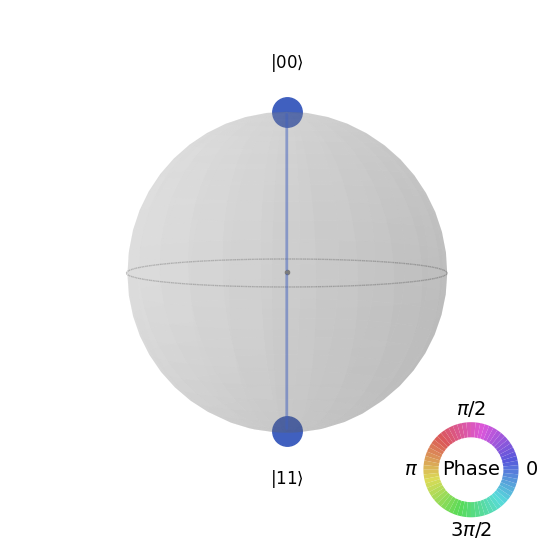

In [ ]:
# Plot the QSphere
psi  = result_state.get_statevector(qc_bell)
plot_state_qsphere(psi)

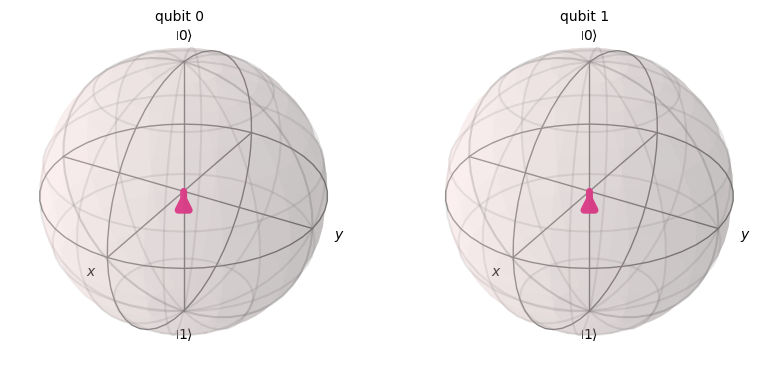

In [ ]:
display(plot_bloch_multivector(psi))

In [ ]:
# Set the Aer simulator as Unitary for Unitary Operator
backend = Aer.get_backend('unitary_simulator')

# Execute the circuit
bell_unitary = backend.run(job_state)
bell_unitary.result().get_unitary(qc_bell, decimals=3)

Operator([[ 0.707+0.j,  0.707-0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j, -0.707+0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j,  0.707-0.j],
          [ 0.707+0.j, -0.707+0.j,  0.   +0.j,  0.   +0.j]],
         input_dims=(2, 2), output_dims=(2, 2))


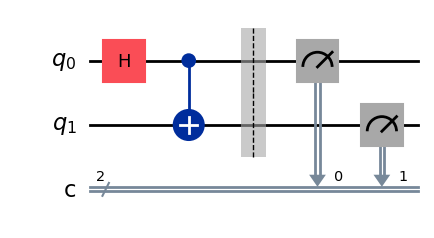

In [ ]:
# The Bell State
qc_bell = QuantumCircuit(2,2,name="qc")
qc_bell.h(0) # H Gate on 1st Qubit
qc_bell.cx(0,1) # CNOT with 1st as Control and 2nd as Target
qc_bell.barrier()
qc_bell.measure([0,1],[0,1])
qc_bell.draw(output='mpl')


Total counts are: {'00': 499, '11': 501}


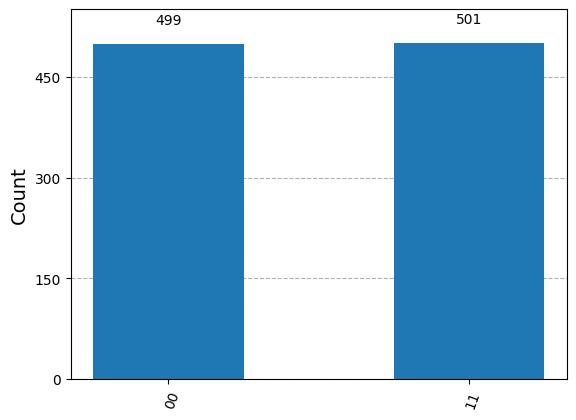

In [ ]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_bell, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc_bell)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

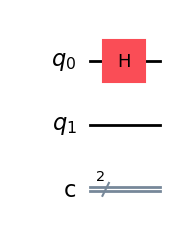

In [ ]:
# Create a circuit with superposition on qubit 0, but no CNOT to entangle it with qubit 1.
# The state will be (|00> + |10>) / sqrt(2)
qc_superposition = QuantumCircuit(2, 2, name="superposition")
qc_superposition.h(0)
# We deliberately omit the qc_superposition.cx(0,1)
qc_superposition.draw(output='mpl')



Quantum state is: Statevector([0.70710678+0.j, 0.70710678+0.j, 0.        +0.j,
             0.        +0.j],
            dims=(2, 2))
Notice the amplitudes are for |00> and |10>, not |00> and |11>.


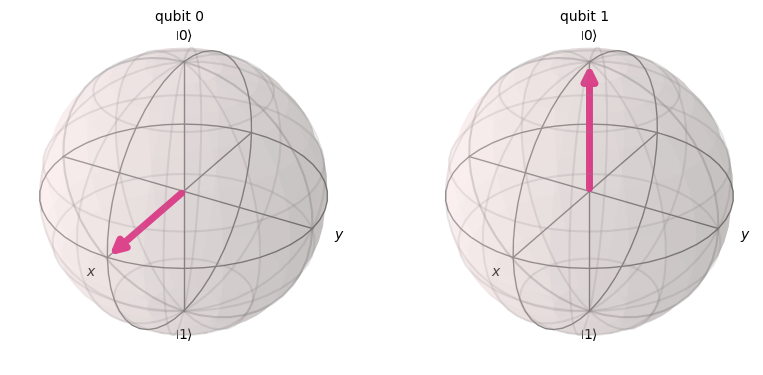

In [ ]:

job_state_sep = transpile(qc_superposition, simulator_state)
result_state_sep = simulator_state.run(job_state_sep).result()
psi_sep = result_state_sep.get_statevector(qc_superposition)

print("\nQuantum state is:", psi_sep)
print("Notice the amplitudes are for |00> and |10>, not |00> and |11>.")

display(plot_bloch_multivector(psi_sep))


In [ ]:
backend_unitary = Aer.get_backend('unitary_simulator')
job_unitary_sep = transpile(qc_superposition, backend_unitary)
unitary_sep = backend_unitary.run(job_unitary_sep).result().get_unitary(qc_superposition, decimals=3)
print("\nUnitary of the non-entangled circuit:")
print(unitary_sep)



Unitary of the non-entangled circuit:
Operator([[ 0.707+0.j,  0.707-0.j,  0.   +0.j,  0.   +0.j],
          [ 0.707+0.j, -0.707+0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j,  0.707-0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j, -0.707+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))


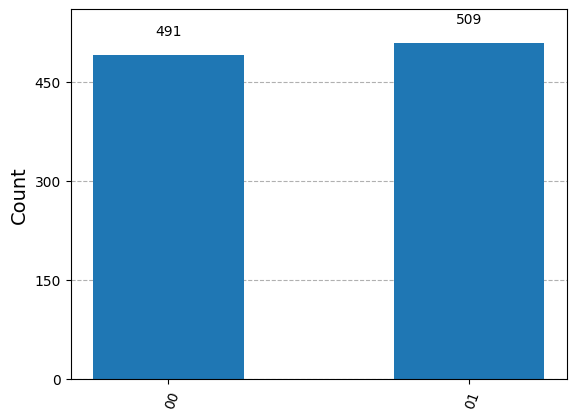

In [ ]:
qc_superposition.barrier()
qc_superposition.measure([0,1],[0,1])

backend_qasm = Aer.get_backend('qasm_simulator')
job_qasm_sep = backend_qasm.run(transpile(qc_superposition, backend_qasm), shots=1000)
counts_sep = job_qasm_sep.result().get_counts(qc_superposition)

plot_histogram(counts_sep)